# Predicting Employee Retention with Logistic Regression

### Problem statement
A mid-sized technology company faces high employee turnover, which disrupts projects and raises recruitment costs. Exit interviews are reactive: they happen after an employee has decided to leave. HR wants a data-driven way to identify employees at risk of leaving early enough to intervene.

### Objective
Build a logistic regression model that estimates each employee's probability of leaving from demographic, job, performance and workplace-sentiment data. Choose a probability cut-off that suits a retention programme, and evaluate the model on a held-out validation set.

### Steps
1. Data preparation
2. Data cleaning
3. Train-validation split
4. EDA on the training set
5. Checking validation EDA against training EDA
6. Feature engineering
7. Model building: scaling, RFE, statsmodels logit, VIF and p-value pruning, optimal cut-off
8. Prediction and evaluation on the validation set
9. Extensions: drivers as odds ratios, a benchmark against a full model and gradient boosting, and a risk-decile view for HR

## Step 1: Data Preparation

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, precision_recall_curve)

RANDOM_STATE = 42
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); plt.rcParams.update({'figure.dpi': 110})
pd.set_option('display.max_columns', 40)

In [2]:
emp = pd.read_csv('../data/Employee_data.csv')
print('Shape:', emp.shape)
display(emp.head())
emp.info()

Shape: (74610, 24)


,Employee ID,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,Overtime,Distance from Home,Education Level,Marital Status,Number of Dependents,Job Level,Company Size,Company Tenure (In Months),Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition,Attrition
0,8410,31,Male,19,Education,5390,Excellent,Medium,Average,2,No,22.0,Associate Degree,Married,0,Mid,Medium,89.0,No,No,No,Excellent,Medium,Stayed
1,64756,59,Female,4,Media,5534,Poor,High,Low,3,No,21.0,Masterâ€™s Degree,Divorced,3,Mid,Medium,21.0,No,No,No,Fair,Low,Stayed
2,30257,24,Female,10,Healthcare,8159,Good,High,Low,0,No,11.0,Bachelorâ€™s Degree,Married,3,Mid,Medium,74.0,No,No,No,Poor,Low,Stayed
3,65791,36,Female,7,Education,3989,Good,High,High,1,No,27.0,High School,Single,2,Mid,Small,50.0,Yes,No,No,Good,Medium,Stayed
4,65026,56,Male,41,Education,4821,Fair,Very High,Average,0,Yes,71.0,High School,Divorced,0,Senior,Medium,68.0,No,No,No,Fair,Medium,Stayed


<class 'pandas.DataFrame'>
RangeIndex: 74610 entries, 0 to 74609
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee ID                 74610 non-null  int64  
 1   Age                         74610 non-null  int64  
 2   Gender                      74610 non-null  str    
 3   Years at Company            74610 non-null  int64  
 4   Job Role                    74610 non-null  str    
 5   Monthly Income              74610 non-null  int64  
 6   Work-Life Balance           74610 non-null  str    
 7   Job Satisfaction            74610 non-null  str    
 8   Performance Rating          74610 non-null  str    
 9   Number of Promotions        74610 non-null  int64  
 10  Overtime                    74610 non-null  str    
 11  Distance from Home          72698 non-null  float64
 12  Education Level             74610 non-null  str    
 13  Marital Status              74610 non-null

In [3]:
display(emp.describe().T.round(1))
print('Missing values:'); print(emp.isna().sum()[emp.isna().sum() > 0].to_string())
print('\nExact duplicate rows:', emp.duplicated().sum(), '| duplicate Employee IDs:', emp['Employee ID'].duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
Employee ID,74610.0,37246.0,21505.8,1.0,18624.2,37239.5,55871.8,74498.0
Age,74610.0,38.5,12.1,18.0,28.0,39.0,49.0,59.0
Years at Company,74610.0,15.7,11.2,1.0,7.0,13.0,23.0,51.0
Monthly Income,74610.0,7344.9,2596.4,1226.0,5652.0,7348.5,8876.0,50030.0
Number of Promotions,74610.0,0.8,1.0,0.0,0.0,1.0,2.0,4.0
Distance from Home,72698.0,50.0,28.5,1.0,25.0,50.0,75.0,99.0
Number of Dependents,74610.0,1.7,1.6,0.0,0.0,1.0,3.0,15.0
Company Tenure (In Months),72197.0,55.7,25.4,2.0,36.0,56.0,76.0,128.0


Missing values:
Distance from Home            1912
Company Tenure (In Months)    2413



Exact duplicate rows: 112 | duplicate Employee IDs: 112


**Observation:** 74,610 employee records with 24 columns. `Distance from Home` (1,912 rows) and `Company Tenure (In Months)` (2,413 rows) have missing values. There are 112 exact duplicate rows, each repeating an Employee ID.

## Step 2: Data Cleaning
### 2.1 Duplicates and text-encoding errors

In [4]:
emp = emp.drop_duplicates().reset_index(drop=True)
print('Rows after removing exact duplicates:', len(emp))
# The file stores the apostrophe in "Bachelor's" / "Master's" as mis-decoded UTF-8 ("â€™").
print('Before:', sorted(emp['Education Level'].unique()))
emp['Education Level'] = emp['Education Level'].str.replace('â€™', "'", regex=False)
print('After: ', sorted(emp['Education Level'].unique()))

Rows after removing exact duplicates: 74498
Before: ['Associate Degree', 'Bachelorâ€™s Degree', 'High School', 'Masterâ€™s Degree', 'PhD']
After:  ['Associate Degree', "Bachelor's Degree", 'High School', "Master's Degree", 'PhD']


**Observation:** Removing the 112 duplicates leaves 74,498 employees. The education labels contained a mis-decoded apostrophe (`Bachelorâ€™s`). It is repaired so the categories read correctly in every table and chart.

### 2.2 Missing values
`Distance from Home` (about 2.6%) and `Company Tenure (In Months)` (about 3.2%) have missing values. First, check whether missingness is related to the target. Imputation happens **after** the split, using training-set medians, so no information leaks from the validation set.

In [5]:
for col in ['Distance from Home', 'Company Tenure (In Months)']:
    miss = emp[col].isna()
    print(f'{col}: {miss.mean():.2%} missing | attrition rate when missing = {(emp.loc[miss, "Attrition"] == "Left").mean():.3f}, '
          f'when present = {(emp.loc[~miss, "Attrition"] == "Left").mean():.3f}')

Distance from Home: 2.55% missing | attrition rate when missing = 0.450, when present = 0.475
Company Tenure (In Months): 3.20% missing | attrition rate when missing = 0.374, when present = 0.478


**Observation:** Missingness is not random for tenure. Employees with missing `Company Tenure` left at a rate of 37.4%, against 47.8% when it is present. Median imputation loses that signal, but the effect is small (3.2% of rows). A missing-indicator column is a possible refinement.

### 2.3 Redundant columns and category values

In [6]:
emp = emp.drop(columns='Employee ID')   # identifier, no predictive meaning
for c in emp.select_dtypes(exclude='number').columns:
    print(f'{c:28s}', emp[c].value_counts().to_dict())
# Sanity check on two tenure fields that should agree
print('\nYears at Company > Company Tenure (years):',
      (emp['Years at Company'] > emp['Company Tenure (In Months)'] / 12).mean().round(3))

Gender                       {'Male': 40826, 'Female': 33672}
Job Role                     {'Technology': 19322, 'Healthcare': 17074, 'Education': 15658, 'Media': 11996, 'Finance': 10448}
Work-Life Balance            {'Good': 28158, 'Fair': 22529, 'Excellent': 13432, 'Poor': 10379}
Job Satisfaction             {'High': 37245, 'Very High': 15079, 'Medium': 14717, 'Low': 7457}
Performance Rating           {'Average': 44719, 'High': 14910, 'Below Average': 11139, 'Low': 3730}
Overtime                     {'No': 50157, 'Yes': 24341}
Education Level              {"Bachelor's Degree": 22331, 'Associate Degree': 18649, "Master's Degree": 15021, 'High School': 14680, 'PhD': 3817}
Marital Status               {'Married': 37419, 'Single': 26001, 'Divorced': 11078}
Job Level                    {'Entry': 29780, 'Mid': 29678, 'Senior': 15040}
Company Size                 {'Medium': 37231, 'Small': 22355, 'Large': 14912}
Remote Work                  {'No': 60300, 'Yes': 14198}
Leadership Opportuniti


Years at Company > Company Tenure (years): 0.843


**Observation:** The categorical columns have clean, consistent levels. One data-quality flag: for 84% of employees, `Years at Company` exceeds `Company Tenure` converted to years, which should be impossible if both measure time at this company. The two fields cannot both be correct, which suggests the dataset is synthetic. Neither field ends up in the final model.

## Step 3: Train-Validation Split
A stratified 70/30 split is made, then numeric missing values are imputed with training medians.

In [7]:
y_all = (emp['Attrition'] == 'Left').astype(int)       # 1 = left (the event HR wants to anticipate)
X_all = emp.drop(columns='Attrition')
X_train, X_val, y_train, y_val = train_test_split(X_all, y_all, test_size=0.3, stratify=y_all, random_state=RANDOM_STATE)
medians = X_train[['Distance from Home', 'Company Tenure (In Months)']].median()
X_train = X_train.fillna(medians); X_val = X_val.fillna(medians)
print(f'Train: {X_train.shape} | Validation: {X_val.shape} | attrition rate train/val: {y_train.mean():.3f} / {y_val.mean():.3f}')
print('Imputation medians (train):', medians.to_dict())

Train: (52148, 22) | Validation: (22350, 22) | attrition rate train/val: 0.475 / 0.475
Imputation medians (train): {'Distance from Home': 50.0, 'Company Tenure (In Months)': 56.0}


## Step 4: EDA on the Training Set
### 4.1 Univariate analysis

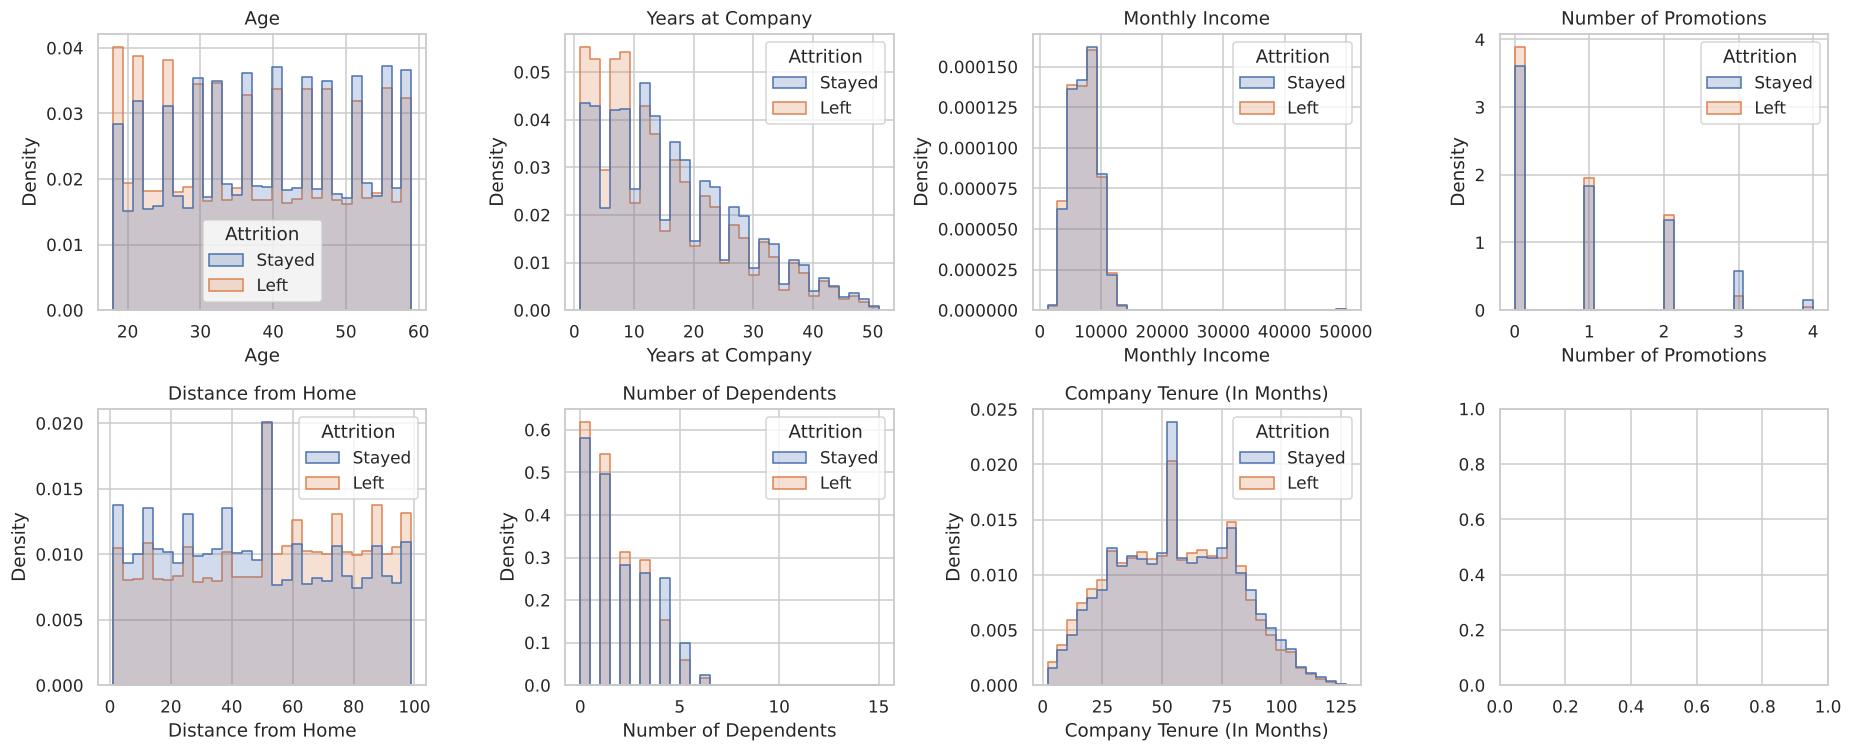

In [8]:
NUM_COLS = X_train.select_dtypes(include='number').columns.tolist()
train_df = X_train.assign(Attrition=y_train.map({1: 'Left', 0: 'Stayed'}))
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(data=train_df, x=col, hue='Attrition', bins=30, element='step', stat='density', common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.savefig(FIG_DIR / 'numeric_distributions.png', bbox_inches='tight'); plt.show()

**Observation:** The numeric distributions of leavers and stayers overlap almost completely. Leavers are slightly younger (37.9 vs 39.1 years), have slightly shorter tenure (14.9 vs 16.4 years) and live slightly farther away. No single numeric variable separates the groups.

### 4.2 Correlations

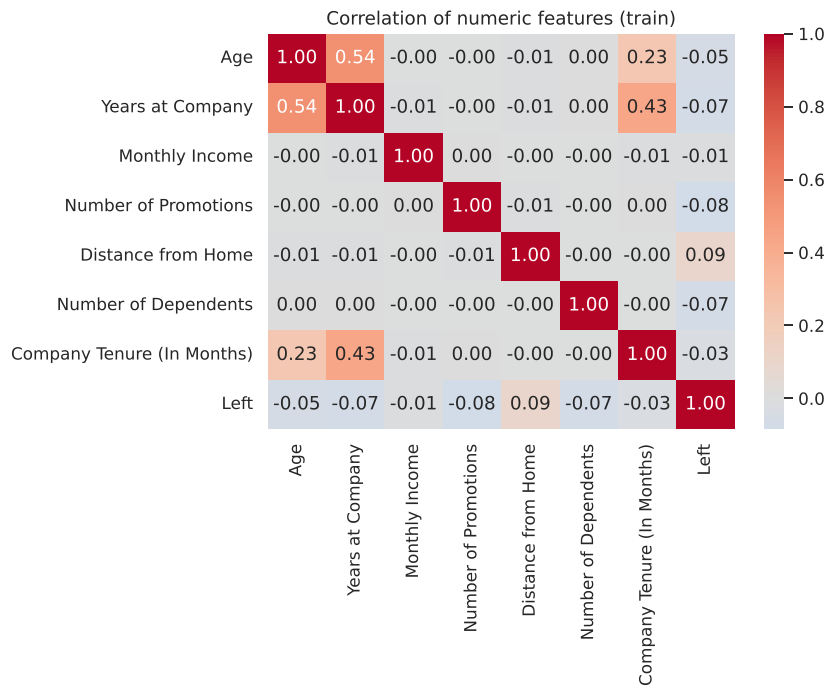

In [9]:
corr = train_df[NUM_COLS].assign(Left=y_train).corr()
plt.figure(figsize=(8, 6.5)); sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric features (train)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'correlation_heatmap.png', bbox_inches='tight'); plt.show()

**Observation:** Every numeric feature correlates only weakly with leaving (|r| ≤ 0.09; distance from home is the largest at +0.09). The only notable correlation between predictors is age with years at company (0.54), which is well below multicollinearity concern.

### 4.3 Data balance

In [10]:
bal = y_train.map({1: 'Left', 0: 'Stayed'}).value_counts(normalize=True).round(3)
display(bal.to_frame('Share'))

,Share
Attrition,
Stayed,0.525
Left,0.475


**Observation:** The classes are nearly balanced (47.5% left), so no resampling is needed, and accuracy, sensitivity and specificity are all meaningful.

### 4.4 Categorical columns vs attrition

,Feature,Lowest-rate level,Highest-rate level,Spread (pts)
8,Job Level,Senior (20%),Entry (63%),43.2
7,Marital Status,Married (36%),Single (67%),30.5
10,Remote Work,Yes (25%),No (53%),28.2
6,Education Level,PhD (24%),Associate Degree (49%),25.5
2,Work-Life Balance,Excellent (36%),Poor (60%),23.9
13,Company Reputation,Good (43%),Poor (56%),12.8
4,Performance Rating,Average (46%),Low (57%),11.3
0,Gender,Male (43%),Female (53%),9.8
3,Job Satisfaction,High (45%),Very High (53%),8.0
5,Overtime,No (46%),Yes (51%),5.9


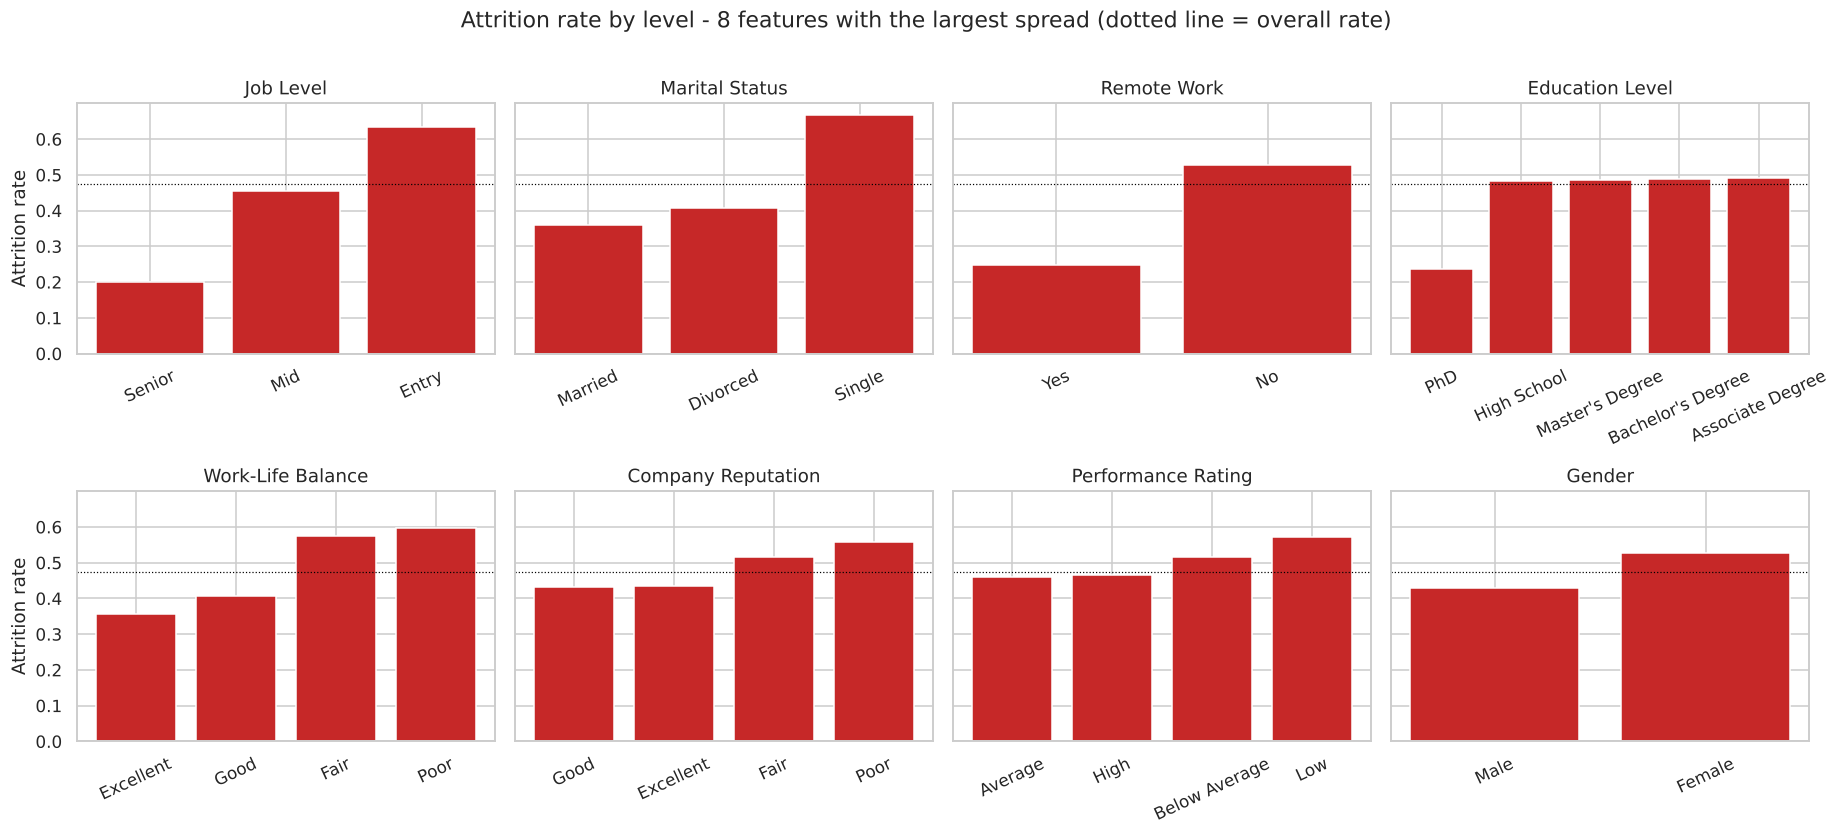

In [11]:
CAT_COLS = X_train.select_dtypes(exclude='number').columns.tolist()
rates = []
for c in CAT_COLS:
    r = y_train.groupby(X_train[c]).mean()
    rates.append({'Feature': c, 'Lowest-rate level': f'{r.idxmin()} ({r.min():.0%})',
                  'Highest-rate level': f'{r.idxmax()} ({r.max():.0%})', 'Spread (pts)': round(100 * (r.max() - r.min()), 1)})
rate_tbl = pd.DataFrame(rates).sort_values('Spread (pts)', ascending=False)
display(rate_tbl)
rate_tbl.to_csv(MET_DIR / 'attrition_rate_spread_by_category.csv', index=False)

top = rate_tbl['Feature'].head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharey=True)
for ax, c in zip(axes.ravel(), top):
    r = y_train.groupby(X_train[c]).mean().sort_values()
    ax.bar(r.index.astype(str), r.values, color='#C62828'); ax.set_title(c); ax.tick_params(axis='x', labelrotation=25)
    ax.axhline(y_train.mean(), color='black', ls=':', lw=0.8)
axes[0, 0].set_ylabel('Attrition rate'); axes[1, 0].set_ylabel('Attrition rate')
plt.suptitle('Attrition rate by level - 8 features with the largest spread (dotted line = overall rate)', y=1.01)
plt.tight_layout(); plt.savefig(FIG_DIR / 'attrition_by_category.png', bbox_inches='tight'); plt.show()

**Observation:** The categorical features carry the signal. Job level shows a 43-point spread in attrition (entry 63% vs senior 20%), followed by marital status (single 67% vs married 36%), remote work (on-site 53% vs remote 25%), education (PhD 24%) and work-life balance (poor 60% vs excellent 36%). Job role, recognition and leadership opportunities barely matter (< 3 points).

## Step 5: Validation EDA vs Training EDA
The validation set should look like the training set. Numeric distributions are compared with a two-sample Kolmogorov-Smirnov test, and category attrition rates are compared directly.

In [12]:
ks = pd.DataFrame({c: ks_2samp(X_train[c], X_val[c]) for c in NUM_COLS}, index=['KS statistic', 'p-value']).T.round(4)
display(ks)
cat_cmp = pd.DataFrame({c: [(y_train.groupby(X_train[c]).mean() - y_val.groupby(X_val[c]).mean()).abs().max()] for c in CAT_COLS},
                       index=['Max |train - val| attrition-rate difference']).T.round(3)
display(cat_cmp.sort_values(cat_cmp.columns[0], ascending=False).head(5))

,KS statistic,p-value
Age,0.0061,0.6005
Years at Company,0.0045,0.9047
Monthly Income,0.0053,0.7666
Number of Promotions,0.0058,0.6729
Distance from Home,0.0076,0.3258
Number of Dependents,0.0026,0.9999
Company Tenure (In Months),0.0083,0.2322


,Max |train - val| attrition-rate difference
Education Level,0.026
Work-Life Balance,0.017
Employee Recognition,0.016
Job Role,0.014
Performance Rating,0.012


**Observation:** The validation set matches the training set. All Kolmogorov-Smirnov statistics are below 0.01 (every p-value > 0.2), and category-level attrition rates differ by at most 2.6 points. The split is representative.

## Step 6: Feature Engineering
### 6.1 Dummy variables for predictors
Binary Yes/No columns become 0/1, and multi-level categoricals become dummies with the first level dropped.
### 6.2 Target variable
The target is already encoded: `Attrition` Left = 1, Stayed = 0 (Step 3).

In [13]:
def encode(df, ref_cols=None):
    out = df.copy()
    for c in ['Overtime', 'Remote Work', 'Leadership Opportunities', 'Innovation Opportunities']:
        out[c] = (out[c] == 'Yes').astype(int)
    out['Gender'] = (out['Gender'] == 'Male').astype(int)
    multi = [c for c in out.select_dtypes(exclude='number').columns]
    out = pd.get_dummies(out, columns=multi, drop_first=True, dtype=int)
    out.columns = [c.replace(' ', '_').replace("'", '').replace('-', '_').replace('(', '').replace(')', '') for c in out.columns]
    return out if ref_cols is None else out.reindex(columns=ref_cols, fill_value=0)

X_train_d = encode(X_train); X_val_d = encode(X_val, X_train_d.columns)
print('Encoded predictors:', X_train_d.shape[1])
print(list(X_train_d.columns))

Encoded predictors: 41
['Age', 'Gender', 'Years_at_Company', 'Monthly_Income', 'Number_of_Promotions', 'Overtime', 'Distance_from_Home', 'Number_of_Dependents', 'Company_Tenure_In_Months', 'Remote_Work', 'Leadership_Opportunities', 'Innovation_Opportunities', 'Job_Role_Finance', 'Job_Role_Healthcare', 'Job_Role_Media', 'Job_Role_Technology', 'Work_Life_Balance_Fair', 'Work_Life_Balance_Good', 'Work_Life_Balance_Poor', 'Job_Satisfaction_Low', 'Job_Satisfaction_Medium', 'Job_Satisfaction_Very_High', 'Performance_Rating_Below_Average', 'Performance_Rating_High', 'Performance_Rating_Low', 'Education_Level_Bachelors_Degree', 'Education_Level_High_School', 'Education_Level_Masters_Degree', 'Education_Level_PhD', 'Marital_Status_Married', 'Marital_Status_Single', 'Job_Level_Mid', 'Job_Level_Senior', 'Company_Size_Medium', 'Company_Size_Small', 'Company_Reputation_Fair', 'Company_Reputation_Good', 'Company_Reputation_Poor', 'Employee_Recognition_Low', 'Employee_Recognition_Medium', 'Employee_R

## Step 7: Model Building
### 7.1 Feature scaling

In [14]:
SCALE = [c.replace(' ', '_').replace('(', '').replace(')', '') for c in NUM_COLS]
scaler = StandardScaler().fit(X_train_d[SCALE])
X_train_s, X_val_s = X_train_d.copy(), X_val_d.copy()
X_train_s[SCALE] = scaler.transform(X_train_d[SCALE]); X_val_s[SCALE] = scaler.transform(X_val_d[SCALE])
display(X_train_s[SCALE].describe().loc[['mean', 'std']].round(2))

,Age,Years_at_Company,Monthly_Income,Number_of_Promotions,Distance_from_Home,Number_of_Dependents,Company_Tenure_In_Months
mean,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### 7.2 Feature selection with RFE
Recursive feature elimination keeps 15 predictors as the starting point for manual pruning.

In [15]:
rfe = RFE(LogisticRegression(max_iter=2000), n_features_to_select=15).fit(X_train_s, y_train)
rfe_tbl = pd.DataFrame({'Feature': X_train_s.columns, 'Selected': rfe.support_, 'Rank': rfe.ranking_}).sort_values('Rank')
display(rfe_tbl.head(20))
selected = X_train_s.columns[rfe.support_].tolist()

,Feature,Selected,Rank
1,Gender,True,1
5,Overtime,True,1
9,Remote_Work,True,1
22,Performance_Rating_Below_Average,True,1
21,Job_Satisfaction_Very_High,True,1
19,Job_Satisfaction_Low,True,1
18,Work_Life_Balance_Poor,True,1
28,Education_Level_PhD,True,1
24,Performance_Rating_Low,True,1
31,Job_Level_Mid,True,1


**Observation:** RFE keeps 15 features, all of them categorical dummies (job level, marital status, remote work, work-life balance, education, performance, satisfaction, reputation, overtime and gender). No numeric variable survives, which matches the weak correlations seen in EDA.

### 7.3 Logistic regression (statsmodels): prune by p-value and VIF
Refit repeatedly, dropping the weakest feature while any p-value > 0.05 or any VIF > 5.

In [16]:
def vif(df):
    Xc = sm.add_constant(df)
    return pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(df.shape[1])], index=df.columns)

cols = selected.copy(); step = 0
while True:
    logit = sm.GLM(y_train, sm.add_constant(X_train_s[cols]), family=sm.families.Binomial()).fit()
    p = logit.pvalues.drop('const'); v = vif(X_train_s[cols])
    if p.max() > 0.05:
        drop, why = p.idxmax(), f'p = {p.max():.3f}'
    elif v.max() > 5:
        drop, why = v.idxmax(), f'VIF = {v.max():.2f}'
    else:
        break
    step += 1; print(f'Step {step}: drop {drop} ({why})'); cols.remove(drop)
print(f'\nFinal model: {len(cols)} features | max p-value {p.max():.2e} | max VIF {v.max():.2f}')
print(logit.summary())


Final model: 15 features | max p-value 1.82e-26 | max VIF 1.20
                 Generalized Linear Model Regression Results                  
Dep. Variable:              Attrition   No. Observations:                52148
Model:                            GLM   Df Residuals:                    52132
Model Family:                Binomial   Df Model:                           15
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -26376.
Date:                Sat, 07 Nov 2026   Deviance:                       52751.
Time:                        04:53:16   Pearson chi2:                 4.89e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.3108
Covariance Type:            nonrobust                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------

**Observation:** All 15 RFE features are retained. Every p-value is far below 0.05 (largest 1.8e-26) and every VIF is at most 1.20, so no pruning step is triggered.

In [17]:
final_or = pd.DataFrame({'Coef': logit.params, 'Odds ratio': np.exp(logit.params),
                         'OR 2.5%': np.exp(logit.conf_int()[0]), 'OR 97.5%': np.exp(logit.conf_int()[1]),
                         'VIF': vif(X_train_s[cols]).reindex(logit.params.index)}).drop('const')
final_or = final_or.reindex(final_or['Coef'].abs().sort_values(ascending=False).index).round(3)
display(final_or)
final_or.to_csv(MET_DIR / 'final_model_odds_ratios.csv')

train_prob = logit.predict(sm.add_constant(X_train_s[cols]))
def metric_row(y, prob, cut):
    pred = (prob >= cut).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'Accuracy': (tp + tn) / len(y), 'Sensitivity': tp / (tp + fn), 'Specificity': tn / (tn + fp),
            'Precision': tp / (tp + fp), 'F1': f1_score(y, pred), 'ROC-AUC': roc_auc_score(y, prob)}
display(pd.Series(metric_row(y_train, train_prob, 0.5), name='Train @ 0.5').round(3).to_frame())

,Coef,Odds ratio,OR 2.5%,OR 97.5%,VIF
Job_Level_Senior,-2.533,0.079,0.074,0.085,1.202
Remote_Work,-1.708,0.181,0.171,0.192,1.000
Marital_Status_Single,1.686,5.399,5.151,5.659,1.000
Education_Level_PhD,-1.584,0.205,0.184,0.228,1.000
Work_Life_Balance_Poor,1.224,3.402,3.190,3.628,1.075
Work_Life_Balance_Fair,1.076,2.932,2.794,3.077,1.075
Job_Level_Mid,-0.961,0.382,0.365,0.400,1.202
Company_Reputation_Poor,0.744,2.105,1.994,2.223,1.068
Gender,-0.576,0.562,0.539,0.587,1.000
Performance_Rating_Low,0.562,1.754,1.591,1.933,1.010


,Train @ 0.5
Accuracy,0.741
Sensitivity,0.720
Specificity,0.760
Precision,0.730
F1,0.725
ROC-AUC,0.826


**Observation:** The strongest effects are being senior (OR 0.08 vs entry level), working remotely (OR 0.18), having a PhD (OR 0.21) and being single (OR 5.4). Poor or fair work-life balance raises the odds about 3x relative to excellent. One effect is implausible: *very high* job satisfaction raises the odds of leaving (OR 1.62) almost exactly as much as *low* satisfaction (1.61). The raw data shows the same pattern (53% attrition for both), which again points to synthetic data. At a 0.5 cut-off, training accuracy is 0.741 and AUC 0.826.

### 7.4 Finding the optimal cut-off

,Accuracy,Sensitivity,Specificity,Precision,F1,ROC-AUC
Cut-off,,,,,,
0.10,0.587,0.992,0.221,0.535,0.695,0.826
0.15,0.631,0.975,0.320,0.564,0.715,0.826
0.20,0.659,0.954,0.393,0.587,0.727,0.826
0.25,0.687,0.923,0.473,0.613,0.737,0.826
0.30,0.705,0.900,0.528,0.633,0.743,0.826
0.35,0.724,0.854,0.606,0.662,0.746,0.826
0.40,0.731,0.821,0.651,0.680,0.744,0.826
0.45,0.739,0.765,0.714,0.708,0.735,0.826
0.50,0.741,0.720,0.760,0.730,0.725,0.826


Cut-off where sensitivity = specificity: 0.48


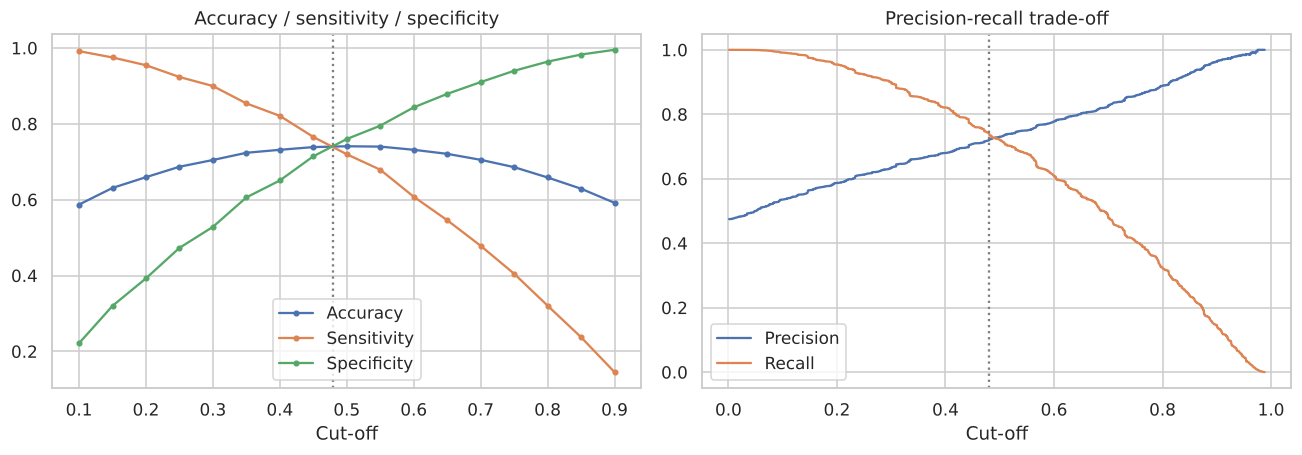

,Train @ 0.48
Accuracy,0.740
Sensitivity,0.735
Specificity,0.745
Precision,0.722
F1,0.729
ROC-AUC,0.826


In [18]:
cuts = np.round(np.arange(0.1, 0.91, 0.05), 2)
cut_tbl = pd.DataFrame([{'Cut-off': c, **metric_row(y_train, train_prob, c)} for c in cuts]).set_index('Cut-off')
display(cut_tbl.round(3))
cut_tbl.round(4).to_csv(MET_DIR / 'cutoff_table_train.csv')
fine = np.round(np.arange(0.2, 0.8, 0.01), 2)
gap = [abs(metric_row(y_train, train_prob, c)['Sensitivity'] - metric_row(y_train, train_prob, c)['Specificity']) for c in fine]
OPT_CUT = float(fine[int(np.argmin(gap))])
print(f'Cut-off where sensitivity = specificity: {OPT_CUT}')

prec, rec, thr = precision_recall_curve(y_train, train_prob)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for col in ['Accuracy', 'Sensitivity', 'Specificity']: axes[0].plot(cut_tbl.index, cut_tbl[col], marker='o', ms=3, label=col)
axes[0].axvline(OPT_CUT, color='grey', ls=':'); axes[0].set_xlabel('Cut-off'); axes[0].set_title('Accuracy / sensitivity / specificity'); axes[0].legend()
axes[1].plot(thr, prec[:-1], label='Precision'); axes[1].plot(thr, rec[:-1], label='Recall')
axes[1].axvline(OPT_CUT, color='grey', ls=':'); axes[1].set_xlabel('Cut-off'); axes[1].set_title('Precision-recall trade-off'); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'cutoff_selection.png', bbox_inches='tight'); plt.show()
display(pd.Series(metric_row(y_train, train_prob, OPT_CUT), name=f'Train @ {OPT_CUT}').round(3).to_frame())

**Observation:** At 0.48, sensitivity and specificity are equal (0.735 / 0.745). For a retention programme, a lower cut-off is defensible if outreach is cheap. At 0.35, the model flags 85% of leavers at a precision of 0.66. The 0.48 cut-off is used for evaluation as a neutral, balanced choice.

## Step 8: Prediction and Evaluation on the Validation Set

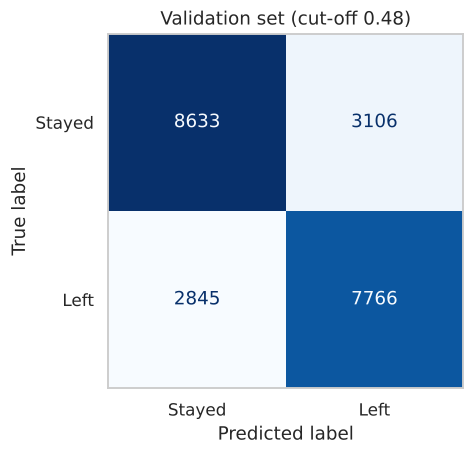

TP=7766  TN=8633  FP=3106  FN=2845


,Train,Validation
Accuracy,0.740,0.734
Sensitivity,0.735,0.732
Specificity,0.745,0.735
Precision,0.722,0.714
F1,0.729,0.723
ROC-AUC,0.826,0.825


In [19]:
val_prob = logit.predict(sm.add_constant(X_val_s[cols], has_constant='add'))
val_pred = (val_prob >= OPT_CUT).astype(int)
tn, fp, fn, tp = confusion_matrix(y_val, val_pred).ravel()
fig, ax = plt.subplots(figsize=(5, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred), display_labels=['Stayed', 'Left']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Validation set (cut-off {OPT_CUT})'); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG_DIR / 'confusion_validation.png', bbox_inches='tight'); plt.show()
val_metrics = pd.DataFrame({'Train': metric_row(y_train, train_prob, OPT_CUT), 'Validation': metric_row(y_val, val_prob, OPT_CUT)}).round(3)
print(f'TP={tp}  TN={tn}  FP={fp}  FN={fn}')
display(val_metrics)
val_metrics.to_csv(MET_DIR / 'train_vs_validation_metrics.csv')

**Observation:** Validation performance matches training almost exactly (accuracy 0.734 vs 0.740, AUC 0.825 vs 0.826), so the model generalises without overfitting. It catches 73.2% of leavers (7,766 of 10,611) with 73.5% specificity. When it flags someone, it is right 71.4% of the time.

# Extensions
## A. What drives attrition?

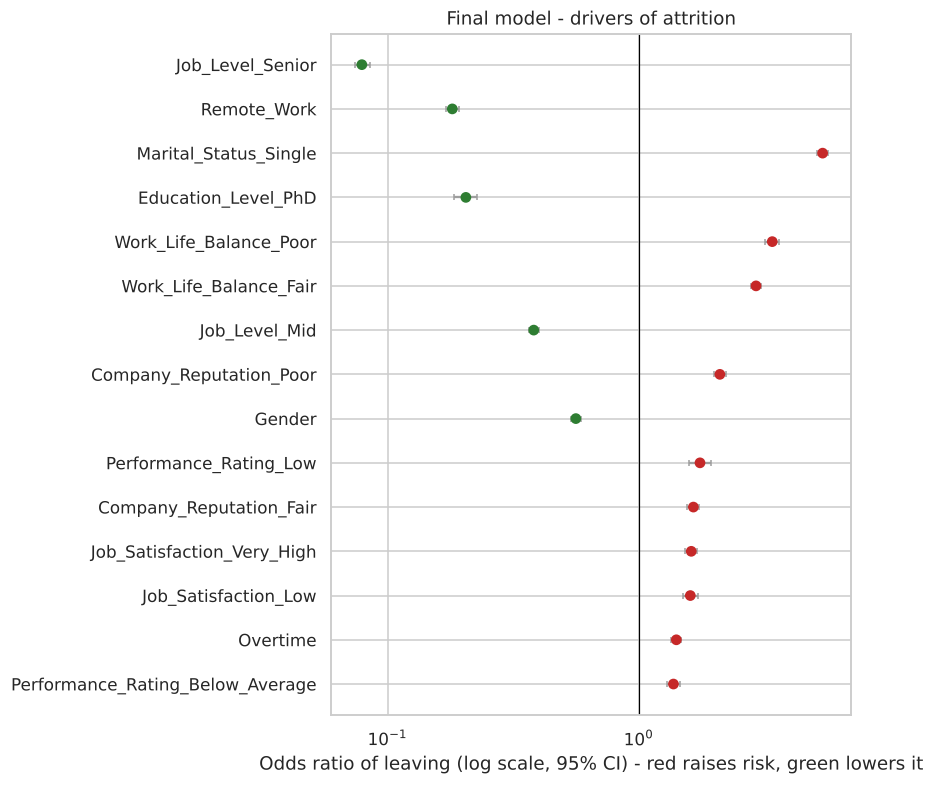

In [20]:
plot_or = final_or.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.42 * len(plot_or) + 1))
colors = ['#C62828' if v > 1 else '#2E7D32' for v in plot_or['Odds ratio']]
ax.errorbar(plot_or['Odds ratio'], plot_or.index, xerr=[plot_or['Odds ratio'] - plot_or['OR 2.5%'], plot_or['OR 97.5%'] - plot_or['Odds ratio']],
            fmt='none', ecolor='#9E9E9E', capsize=2)
ax.scatter(plot_or['Odds ratio'], plot_or.index, c=colors, zorder=3); ax.axvline(1, color='black', lw=0.8); ax.set_xscale('log')
ax.set_xlabel('Odds ratio of leaving (log scale, 95% CI) - red raises risk, green lowers it'); ax.set_title('Final model - drivers of attrition')
plt.tight_layout(); plt.savefig(FIG_DIR / 'attrition_drivers_odds_ratios.png', bbox_inches='tight'); plt.show()

**Observation:** Protective factors (green) are seniority, remote work, a PhD and male gender. Risk factors (red) are being single, poor or fair work-life balance, poor company reputation, low performance ratings, both extremes of job satisfaction, and overtime. Several of the strongest drivers (job level, remote work, work-life balance) can be influenced by HR. Others (marital status, gender) cannot and should not be used for decisions about individuals, which matters for how the model is deployed.

## B. What does feature selection cost?
The pruned model is compared with an L2-regularised logistic regression on all encoded features and with a gradient-boosting model.

In [21]:
full_lr = LogisticRegression(max_iter=3000).fit(X_train_s, y_train)
hgb = HistGradientBoostingClassifier(random_state=RANDOM_STATE).fit(X_train_d, y_train)
bench = pd.DataFrame({
    f'Pruned logit ({len(cols)} features)': metric_row(y_val, val_prob, OPT_CUT),
    f'Logistic, all {X_train_s.shape[1]} features': metric_row(y_val, pd.Series(full_lr.predict_proba(X_val_s)[:, 1], index=y_val.index), OPT_CUT),
    'Gradient boosting (all features)': metric_row(y_val, pd.Series(hgb.predict_proba(X_val_d)[:, 1], index=y_val.index), OPT_CUT)}).round(3)
display(bench)
bench.to_csv(MET_DIR / 'model_benchmark_validation.csv')

,Pruned logit (15 features),"Logistic, all 41 features",Gradient boosting (all features)
Accuracy,0.734,0.748,0.752
Sensitivity,0.732,0.753,0.762
Specificity,0.735,0.744,0.744
Precision,0.714,0.726,0.729
F1,0.723,0.739,0.745
ROC-AUC,0.825,0.840,0.847


**Observation:** Using all 41 encoded features in a regularised logistic model raises validation AUC from 0.825 to 0.840 and accuracy from 0.734 to 0.748. Gradient boosting reaches AUC 0.847. The 15-feature model gives up about 0.02 AUC for a much shorter, fully interpretable driver list. For an HR audience that has to act on and justify the drivers, that trade-off is reasonable.

## C. Risk deciles: how HR would use the scores
Validation employees are ranked by predicted probability of leaving and grouped into ten equal deciles.

,Employees,Mean_predicted,Actual_attrition,Cumulative share of leavers
Risk decile,,,,
1,2235,0.922,0.945,0.199
2,2235,0.825,0.800,0.368
3,2235,0.726,0.691,0.513
4,2235,0.626,0.595,0.638
5,2235,0.524,0.515,0.747
6,2235,0.424,0.450,0.842
7,2235,0.319,0.355,0.917
8,2235,0.220,0.252,0.970
9,2235,0.128,0.126,0.996


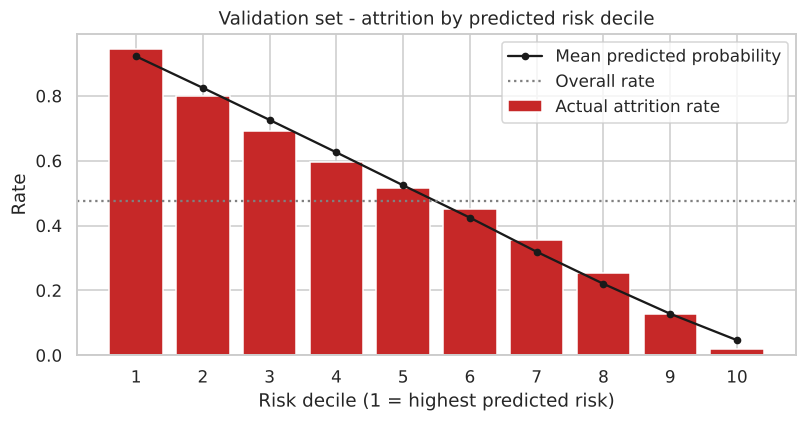

In [22]:
dec = pd.DataFrame({'prob': val_prob.values, 'left': y_val.values})
dec['Risk decile'] = pd.qcut(dec['prob'].rank(method='first', ascending=False), 10, labels=range(1, 11))
dec_tbl = dec.groupby('Risk decile', observed=True).agg(Employees=('left', 'size'), Mean_predicted=('prob', 'mean'), Actual_attrition=('left', 'mean'))
dec_tbl['Cumulative share of leavers'] = dec.groupby('Risk decile', observed=True)['left'].sum().cumsum() / dec['left'].sum()
display(dec_tbl.round(3))
dec_tbl.round(4).to_csv(MET_DIR / 'risk_deciles_validation.csv')
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(dec_tbl.index.astype(str), dec_tbl['Actual_attrition'], color='#C62828', label='Actual attrition rate')
ax.plot(dec_tbl.index.astype(str), dec_tbl['Mean_predicted'], 'ko-', ms=4, label='Mean predicted probability')
ax.axhline(y_val.mean(), color='grey', ls=':', label='Overall rate'); ax.set_xlabel('Risk decile (1 = highest predicted risk)')
ax.set_ylabel('Rate'); ax.set_title('Validation set - attrition by predicted risk decile'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'risk_deciles.png', bbox_inches='tight'); plt.show()

**Observation:** The probabilities are well calibrated: in every decile, mean predicted risk is within about 4 points of the actual rate. The top decile has 94.5% actual attrition, and the bottom decile 1.8%. Focusing retention effort on the top 30% of employees by risk would reach 51% of all leavers.

# Conclusion

| Validation set (cut-off 0.48) | Value |
|---|---|
| Accuracy | 0.734 |
| Sensitivity (leavers caught) | 0.732 |
| Specificity | 0.735 |
| Precision | 0.714 |
| ROC-AUC | 0.825 |

**Findings**
1. Attrition is driven by job level, marital status, remote work, work-life balance and education. None of the numeric variables (income, age, tenure, distance) matter once these are known.
2. The 15-feature model generalises perfectly (train and validation within 0.01) and is well calibrated across risk deciles.
3. A full logistic model or gradient boosting adds about 0.02 AUC. The interpretable model is the better choice for HR decisions.
4. **Deployment caution:** marital status and gender are strong predictors but must not drive decisions about individuals. A deployable version should be refitted without them and checked for fairness.

**Limitations:** Inconsistent tenure fields and a non-monotonic satisfaction effect suggest synthetic data, so drivers may not transfer to a real workforce. The data is a single snapshot with no time dimension, and median imputation discards a small missingness signal.